# CS 521 HW4, Problem 1: IBP Training

**Method.** Network: 3 hidden layers of 50 neurons. IBP passes the box [x−ε, x+ε] ∩ [0,1] through the network with interval arithmetic. The last layer is merged with the spec (Eq. 9). Loss: κ·CE(z, y) + (1−κ)·CE(ẑ, y). After 1 standard epoch, ε goes from 0 to 0.1 and κ from 1 to 0.5 over 10 epochs. Total: 20 epochs.

In [ ]:
import time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, torchvision
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)

def load_mnist(train):
    ds = torchvision.datasets.MNIST("data", train=train, download=True)
    return ds.data.float().div(255).unsqueeze(1).to(device), ds.targets.to(device)

def batches(x, y, bs, shuffle):
    idx = torch.randperm(len(x), device=device) if shuffle else torch.arange(len(x), device=device)
    for i in range(0, len(x), bs):
        yield x[idx[i:i + bs]], y[idx[i:i + bs]]

x_train, y_train = load_mnist(True)
x_test, y_test = load_mnist(False)

def make_model():
    return nn.Sequential(nn.Flatten(),
                         nn.Linear(784, 50), nn.ReLU(), nn.Linear(50, 50), nn.ReLU(),
                         nn.Linear(50, 50), nn.ReLU(), nn.Linear(50, 10)).to(device)

def linears(model):
    return [m for m in model if isinstance(m, nn.Linear)]

In [ ]:
def ibp_spec_logits(model, x, y, eps):
    # Upper bound of z_j - z_y over the box, with the last layer merged into the spec (Eq. 9).
    l, u = (x - eps).clamp(0, 1).flatten(1), (x + eps).clamp(0, 1).flatten(1)
    for layer in linears(model)[:-1]:
        mid, rad = layer((u + l) / 2), ((u - l) / 2) @ layer.weight.abs().t()
        l, u = F.relu(mid - rad), F.relu(mid + rad)
    last = linears(model)[-1]
    W = last.weight.unsqueeze(0) - last.weight[y].unsqueeze(1)   # W_j - W_y
    b = last.bias.unsqueeze(0) - last.bias[y].unsqueeze(1)
    mid, rad = ((u + l) / 2).unsqueeze(2), ((u - l) / 2).unsqueeze(2)
    return (W @ mid).squeeze(2) + (W.abs() @ rad).squeeze(2) + b

EPOCHS, WARMUP, RAMP, EPS = 20, 1, 10, 0.1
ramp = lambda t: 0.0 if t <= WARMUP else min((t - WARMUP) / RAMP, 1.0)

def standard_loss(model, x, y, t):
    return F.cross_entropy(model(x), y)

def ibp_loss(model, x, y, t):
    eps, kappa = EPS * ramp(t), 1 - 0.5 * ramp(t)          # eps: 0 -> 0.1, kappa: 1 -> 0.5
    loss = F.cross_entropy(model(x), y)
    if eps > 0:
        loss = kappa * loss + (1 - kappa) * F.cross_entropy(ibp_spec_logits(model, x, y, eps), y)
    return loss

def train(model, loss_fn, bs=512):
    opt = torch.optim.Adam(model.parameters(), lr=4e-3)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[15], gamma=0.1)
    n = (len(x_train) + bs - 1) // bs
    start = time.time()
    for epoch in range(EPOCHS):
        for i, (x, y) in enumerate(batches(x_train, y_train, bs, True)):
            loss = loss_fn(model, x, y, epoch + i / n)
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    if device.type == "cuda": torch.cuda.synchronize()
    return time.time() - start

std_model, ibp_model = make_model(), make_model()
std_time = train(std_model, standard_loss)
ibp_time = train(ibp_model, ibp_loss)

In [ ]:
def pgd(model, x, y, eps, steps=50, restarts=3):
    alpha, x_adv = 2.5 * eps / steps, x.clone()
    for _ in range(restarts):
        d = (x + (torch.rand_like(x) * 2 - 1) * eps).clamp(0, 1) - x
        for _ in range(steps):
            d.requires_grad_(True)
            g, = torch.autograd.grad(F.cross_entropy(model(x + d), y), d)
            d = ((d + alpha * g.sign()).clamp(-eps, eps) + x).clamp(0, 1).detach() - x
        with torch.no_grad():
            still_ok = model(x_adv).argmax(1) == y      # keep the first successful attack
            x_adv[still_ok] = (x + d)[still_ok]
    return x_adv

def accuracy(model, eps=0.0):
    model.eval(); correct = 0
    for x, y in batches(x_test, y_test, 1000, False):
        if eps > 0: x = pgd(model, x, y, eps)
        with torch.no_grad(): correct += (model(x).argmax(1) == y).sum().item()
    return correct / 100

print(f"{'':10}{'clean':>8}{'PGD eps=0.1':>13}{'train time':>12}")
for name, m, t in [("standard", std_model, std_time), ("IBP", ibp_model, ibp_time)]:
    print(f"{name:10}{accuracy(m):>7.2f}%{accuracy(m, EPS):>12.2f}%{t:>11.1f}s")

             clean  PGD eps=0.1  train time


standard    97.48%        1.10%        7.7s


IBP         94.34%       83.32%       14.9s


**(a)** IBP: 94.3% clean, 83.3% PGD. Standard: 97.5% clean, 1.1% PGD. IBP training took about 2x as long because each step also propagates the bounds.

In [ ]:
@torch.no_grad()
def box_verified(model, x, y, eps):
    # Box verifier: correct and max_j (upper bound of z_j - z_y) < 0.
    z = ibp_spec_logits(model, x, y, eps)
    z[torch.arange(len(y)), y] = -float("inf")
    return (model(x).argmax(1) == y) & (z.max(1).values < 0)

EPS_TEST = np.round(np.linspace(0.01, 0.1, 10), 2)
ver = {e: box_verified(ibp_model, x_test, y_test, float(e)) for e in EPS_TEST}
print("eps_test:         " + "  ".join(f"{e:5.2f}" for e in EPS_TEST))
print("verified acc (%): " + "  ".join(f"{ver[e].float().mean().item() * 100:5.2f}" for e in EPS_TEST))

eps_test:          0.01   0.02   0.03   0.04   0.05   0.06   0.07   0.08   0.09   0.10
verified acc (%): 93.51  92.64  91.65  90.54  89.32  87.86  86.33  84.40  82.14  79.48


eps 0.01:   83 correct but unverified,   71 adversarial examples found


eps 0.02:  170 correct but unverified,  147 adversarial examples found


eps 0.03:  269 correct but unverified,  221 adversarial examples found


eps 0.04:  380 correct but unverified,  320 adversarial examples found


eps 0.05:  502 correct but unverified,  420 adversarial examples found


eps 0.06:  648 correct but unverified,  530 adversarial examples found


eps 0.07:  801 correct but unverified,  642 adversarial examples found


eps 0.08:  994 correct but unverified,  798 adversarial examples found


eps 0.09: 1220 correct but unverified,  933 adversarial examples found


eps 0.10: 1486 correct but unverified, 1126 adversarial examples found


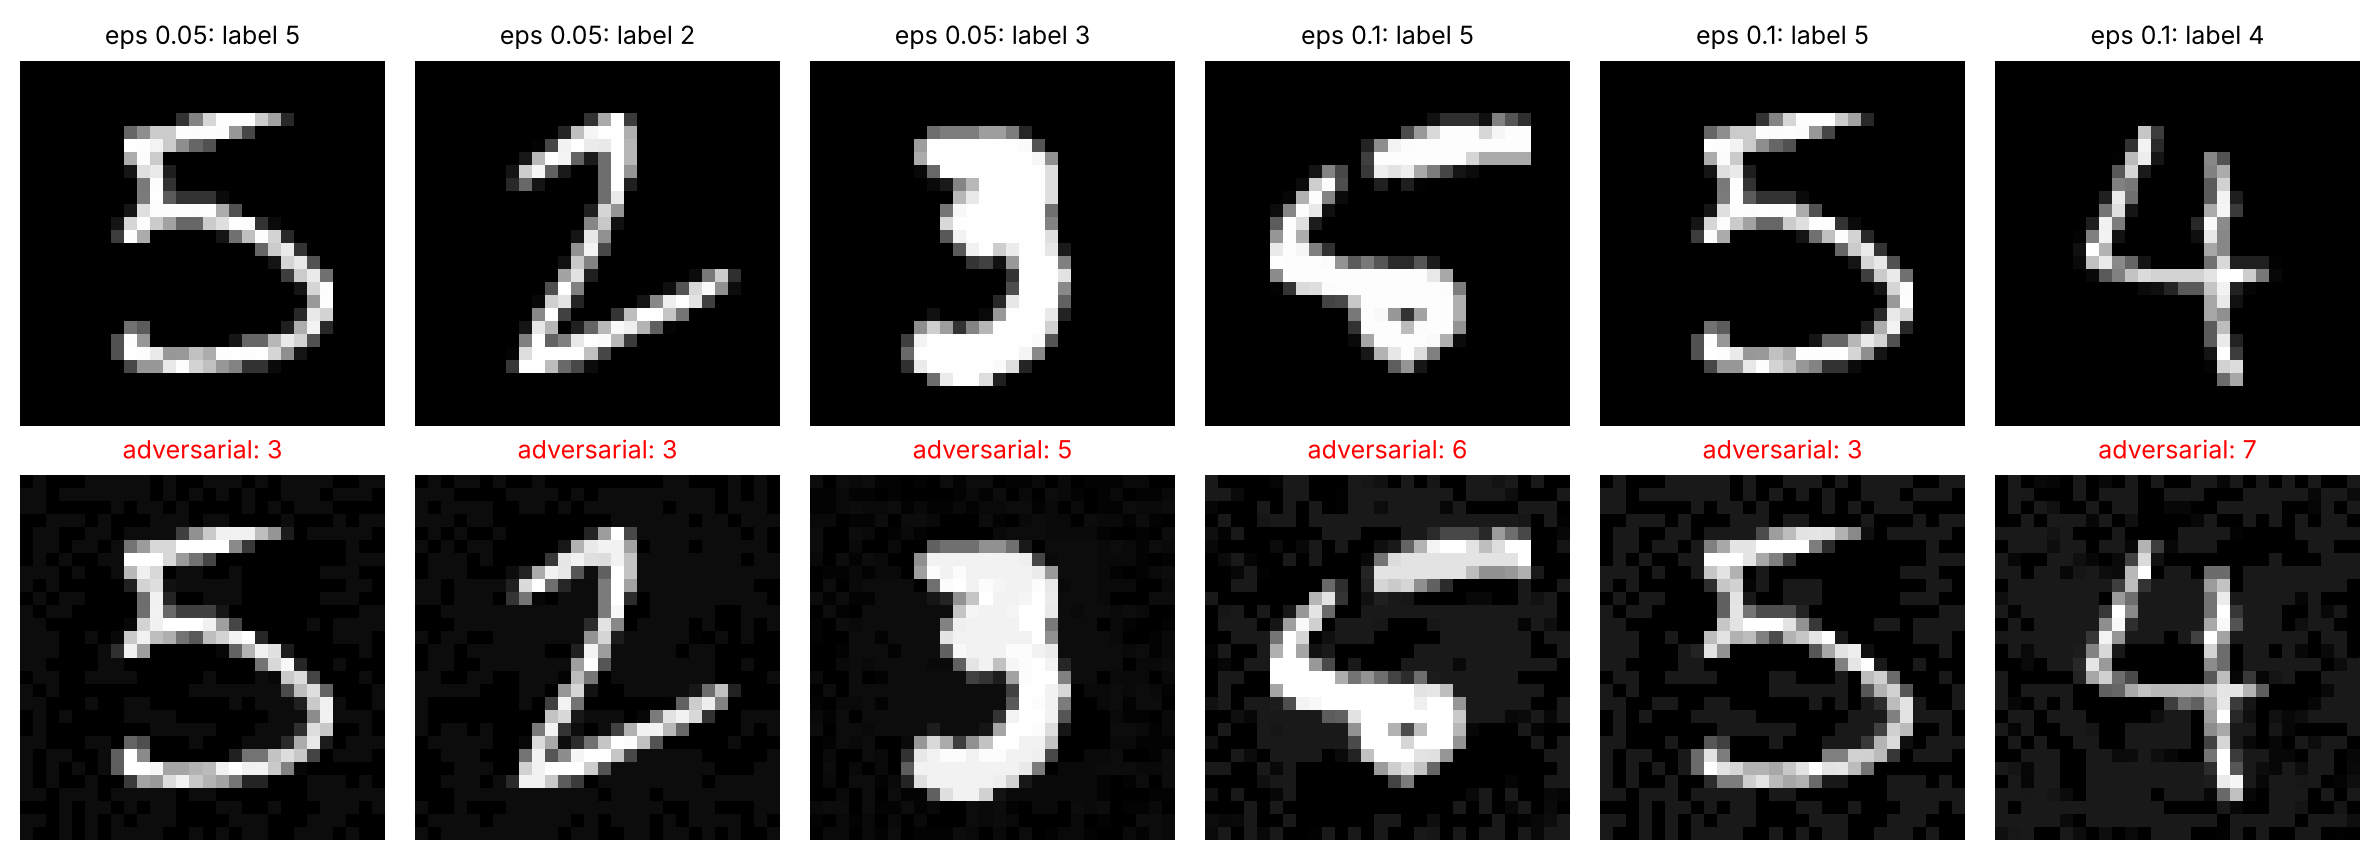

In [ ]:
# Attack the correct but unverified images with a stronger PGD.
with torch.no_grad():
    correct = ibp_model(x_test).argmax(1) == y_test
adv = {}
for e in EPS_TEST:
    idx = torch.nonzero(correct & ~ver[e]).squeeze(1)
    xa = pgd(ibp_model, x_test[idx], y_test[idx], float(e), steps=200, restarts=10)
    with torch.no_grad():
        hit = ibp_model(xa).argmax(1) != y_test[idx]
    adv[e] = (idx[hit], xa[hit])
    print(f"eps {e:.2f}: {len(idx):4d} correct but unverified, {hit.sum().item():4d} adversarial examples found")

fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))
for c, (e, k) in enumerate([(0.05, 0), (0.05, 1), (0.05, 2), (0.1, 0), (0.1, 1), (0.1, 2)]):
    i, xa = adv[e][0][k].item(), adv[e][1][k]
    with torch.no_grad(): p = ibp_model(xa[None]).argmax(1).item()
    ax[0, c].imshow(x_test[i, 0].cpu(), cmap="gray"); ax[0, c].set_title(f"eps {e}: label {y_test[i].item()}", fontsize=9)
    ax[1, c].imshow(xa[0].cpu(), cmap="gray"); ax[1, c].set_title(f"adversarial: {p}", fontsize=9, color="red")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

**(b)** Verified accuracy drops from 93.5% to 79.5%, about 4 points below PGD. Strong PGD breaks most unverified images. These are mostly ambiguous digits, flipped to similar shapes by faint background strokes.